# 01 — Data Audit


In [ ]:
%reload_ext autoreload
%autoreload 2
import os
import sys

sys.path.append('..')
import random

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from PIL import Image
from sklearn.metrics import f1_score
from torch.utils.data import DataLoader
from torchvision import datasets, models, transforms
from tqdm import tqdm

from src.dataset import (
    average_hash,
    build_processed,
    check_no_leakage,
    get_embedding,
    make_imagefolders,
    make_train_val_split,
    md5_hash,
    scan_all_images,
)
from src.model import CNNBaseline
from src.train import evaluate, fit, train_one_epoch
from src.utils import get_device, set_seed

DATA_ROOT='../data/raw/dataset'
os.listdir(DATA_ROOT)





['test', 'train', 'unclean']

In [29]:
# ═══ سلول اول ═══
%load_ext autoreload
%autoreload 2

import sys
sys.path.append('..')

import importlib
import src.dataset
import src.model
import src.utils

# ← این خطا رو force reload می‌کنه
importlib.reload(src.dataset)
importlib.reload(src.model)
importlib.reload(src.utils)

# ← حالا import کن
from src.dataset import (
    average_hash, build_processed, check_no_leakage,
    get_embedding, make_imagefolders, make_train_val_split,
    md5_hash, scan_all_images,
)
from src.model import CNNBaseline
from src.utils import get_device, set_seed

print("✅ همه‌چی reload شد")

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
✅ همه‌چی reload شد


In [ ]:
os.listdir(os.path.join(DATA_ROOT , 'train'))

In [ ]:

os.listdir(os.path.join(DATA_ROOT , 'unclean'))

In [ ]:
def count_classes(split_path):
    counts= {}
    for class_name in sorted(os.listdir(split_path)):
        class_dir = os.path.join (split_path , class_name)
        if os.path.isdir(class_dir):
            counts[class_name] = len(os.listdir(class_dir))
    return counts

train_count = count_classes (os.path.join(DATA_ROOT , 'train'))
print(train_count)

In [ ]:
def count_classes(split_path):
    counts= {}
    for class_name in sorted(os.listdir(split_path)):
        class_dir = os.path.join (split_path , class_name)
        if os.path.isdir(class_dir):
            counts[class_name] = len(os.listdir(class_dir))
    return counts

unclean_count = count_classes (os.path.join(DATA_ROOT , 'unclean'))
print(unclean_count)

In [ ]:
train_classes = set (train_count.keys())
unclean_classes = set (unclean_count.keys())

print("train:" , train_classes - unclean_classes)
print("unclean:" , unclean_classes - train_classes)
print("both:" , train_classes & unclean_classes)


In [ ]:
plt.figure(figsize=(10, 5))
plt.bar(train_count.keys(), train_count.values())
plt.xticks(rotation=45)
plt.title('Class distribution - train')
plt.ylabel('Number of samples')
plt.tight_layout()
plt.show()


In [ ]:
plt.figure(figsize=(10, 5))
plt.bar(unclean_count.keys(), unclean_count.values())
plt.xticks(rotation=45)
plt.title('Class distribution - train')
plt.ylabel('Number of samples')
plt.tight_layout()
plt.show()

## MD5 & Average Hashing:

In [ ]:
records = scan_all_images(DATA_ROOT)
df = pd.DataFrame(records)
print(f"All scanned photos:{len(df)}")

md5_dupes = df [df.duplicated(subset='md5' , keep=False)]. sort_values('md5')
print(f"Duplicate groups with md5 : {md5_dupes['md5'].nunique()}")

avghash_dupes=df[df.duplicated(subset='avghash' , keep=False)].sort_values('avghash')
print(f"Duplicate groups with avghash: {avghash_dupes['avghash'].nunique()}")

def check_label_conflicts(dupes_df , hash_col):
    conflict = []
    for h , group in dupes_df.groupby(hash_col):
        if group['class'].nunique()>1:
            conflict.append(group)
    return conflict

md5_conflicts = check_label_conflicts(md5_dupes , 'md5')
avghash_conflicts=check_label_conflicts(avghash_dupes , 'avghash')
print(f"\nGroups with label conflicts(md5) :{len(md5_conflicts)}")
print(f"\nGroups with label conflicts(avghash): {len(avghash_conflicts)}")


train_df = df[df['split'] == 'train'].copy()
print(f"length of train img {len(train_df)}")



In [ ]:
def rescan(data_root=DATA_ROOT):
    global df
    df = scan_all_images(data_root)
    print(f"🔄 Rescanned: {len(df)} images")
    return df


In [ ]:
counts_by_split_class = df.groupby(['split', 'class']).size().reset_index(name='count')
print(counts_by_split_class.to_string())

print("\n--- جمع کل هر split ---")
print(df.groupby('split').size())

In [ ]:
def show_conflict_group(conflict_groups , group_index=0):
    group = conflict_groups[group_index]
    n = len(group)
    fig , axes = plt.subplots(1 , n , figsize=(4*n , 4))
    if n == 1:
        axes = [axes]
    for ax , (_, row) in zip (axes, group.iterrows()):
        with Image.open(row['path']) as img:
            ax.imshow(img)
        ax.set_title(f"{row['split']}/{row['class']}\n{row['filename']} , fontsize=9")
    plt.tight_layout()
    plt.show()

print("\nmd5 conflict group :")
if md5_conflicts:
    show_conflict_group(md5_conflicts, group_index=0)
else:
    print("No md5 conflicts found!")

for i in range(len(avghash_conflicts)):
    print(f"\n average hash conflicts{i}")
    print("_" * 20)
    show_conflict_group(avghash_conflicts , group_index=i)

## Resnet18:

In [ ]:
df = pd.DataFrame(scan_all_images(DATA_ROOT))
train_df = df[df['split'] == 'train'].copy().reset_index(drop=True)
print(f"train images: {len(train_df)}")


embeddings, valid_idx = [], []
for i, path in enumerate(tqdm(train_df['path'], desc="computing embeddings")):
    try:
        embeddings.append(get_embedding(path))
        valid_idx.append(i)
    except Exception as e:
        print(f"skipped {path}: {e}")

train_df = train_df.iloc[valid_idx].copy().reset_index(drop=True)
train_df['embedding'] = embeddings


train_df['centroid_distance'] = np.nan
for class_name, group in train_df.groupby('class'):
    class_embeddings = np.stack(group['embedding'].values)
    centroid = class_embeddings.mean(axis=0)
    train_df.loc[group.index, 'centroid_distance'] = np.linalg.norm(class_embeddings - centroid, axis=1)

suspects = (
    train_df.sort_values('centroid_distance', ascending=False)
    .groupby('class').head(15)
)



In [ ]:
def show_suspects(suspects_df, class_name, n=15):
    subset = suspects_df[suspects_df['class'] == class_name].head(n)
    cols = 5
    rows = (len(subset) + cols - 1) // cols
    fig, axes = plt.subplots(rows, cols, figsize=(cols*2.5, rows*2.5))
    for ax, (_, row) in zip(axes.flatten(), subset.iterrows()):
        with Image.open(row['path']) as img:
            ax.imshow(img)
        ax.set_title(f"d={row['centroid_distance']:.1f}\n{row['filename']}", fontsize=8)
        ax.axis('off')
    plt.tight_layout()
    plt.show()

show_suspects(suspects, 'ambulance')

In [ ]:
def show_suspects(suspects_df, class_name, n=15):
    subset = suspects_df[suspects_df['class'] == class_name].head(n)
    cols = 5
    rows = (len(subset) + cols - 1) // cols
    fig, axes = plt.subplots(rows, cols, figsize=(cols*2.5, rows*2.5))
    for ax, (_, row) in zip(axes.flatten(), subset.iterrows()):
        with Image.open(row['path']) as img:
            ax.imshow(img)
        ax.set_title(f"d={row['centroid_distance']:.1f}\n{row['filename']}", fontsize=8)
        ax.axis('off')
    plt.tight_layout()
    plt.show()

show_suspects(suspects, 'autobus')

In [ ]:
def show_suspects(suspects_df, class_name, n=15):
    subset = suspects_df[suspects_df['class'] == class_name].head(n)
    cols = 5
    rows = (len(subset) + cols - 1) // cols
    fig, axes = plt.subplots(rows, cols, figsize=(cols*2.5, rows*2.5))
    for ax, (_, row) in zip(axes.flatten(), subset.iterrows()):
        with Image.open(row['path']) as img:
            ax.imshow(img)
        ax.set_title(f"d={row['centroid_distance']:.1f}\n{row['filename']}", fontsize=8)
        ax.axis('off')
    plt.tight_layout()
    plt.show()

show_suspects(suspects, 'kamyun')

In [ ]:
def show_suspects(suspects_df, class_name, n=15):
    subset = suspects_df[suspects_df['class'] == class_name].head(n)
    cols = 5
    rows = (len(subset) + cols - 1) // cols
    fig, axes = plt.subplots(rows, cols, figsize=(cols*2.5, rows*2.5))
    for ax, (_, row) in zip(axes.flatten(), subset.iterrows()):
        with Image.open(row['path']) as img:
            ax.imshow(img)
        ax.set_title(f"d={row['centroid_distance']:.1f}\n{row['filename']}", fontsize=8)
        ax.axis('off')
    plt.tight_layout()
    plt.show()

show_suspects(suspects, 'kamyunet')

In [ ]:
def show_suspects(suspects_df, class_name, n=15):
    subset = suspects_df[suspects_df['class'] == class_name].head(n)
    cols = 5
    rows = (len(subset) + cols - 1) // cols
    fig, axes = plt.subplots(rows, cols, figsize=(cols*2.5, rows*2.5))
    for ax, (_, row) in zip(axes.flatten(), subset.iterrows()):
        with Image.open(row['path']) as img:
            ax.imshow(img)
        ax.set_title(f"d={row['centroid_distance']:.1f}\n{row['filename']}", fontsize=8)
        ax.axis('off')
    plt.tight_layout()
    plt.show()

show_suspects(suspects, 'minibus')

In [ ]:
def show_suspects(suspects_df, class_name, n=15):
    subset = suspects_df[suspects_df['class'] == class_name].head(n)
    cols = 5
    rows = (len(subset) + cols - 1) // cols
    fig, axes = plt.subplots(rows, cols, figsize=(cols*2.5, rows*2.5))
    for ax, (_, row) in zip(axes.flatten(), subset.iterrows()):
        with Image.open(row['path']) as img:
            ax.imshow(img)
        ax.set_title(f"d={row['centroid_distance']:.1f}\n{row['filename']}", fontsize=8)
        ax.axis('off')
    plt.tight_layout()
    plt.show()

show_suspects(suspects, 'savari')

In [ ]:
def show_suspects(suspects_df, class_name, n=15):
    subset = suspects_df[suspects_df['class'] == class_name].head(n)
    cols = 5
    rows = (len(subset) + cols - 1) // cols
    fig, axes = plt.subplots(rows, cols, figsize=(cols*2.5, rows*2.5))
    for ax, (_, row) in zip(axes.flatten(), subset.iterrows()):
        with Image.open(row['path']) as img:
            ax.imshow(img)
        ax.set_title(f"d={row['centroid_distance']:.1f}\n{row['filename']}", fontsize=8)
        ax.axis('off')
    plt.tight_layout()
    plt.show()

show_suspects(suspects, 'taxi')

In [ ]:
def show_suspects(suspects_df, class_name, n=15):
    subset = suspects_df[suspects_df['class'] == class_name].head(n)
    cols = 5
    rows = (len(subset) + cols - 1) // cols
    fig, axes = plt.subplots(rows, cols, figsize=(cols*2.5, rows*2.5))
    for ax, (_, row) in zip(axes.flatten(), subset.iterrows()):
        with Image.open(row['path']) as img:
            ax.imshow(img)
        ax.set_title(f"d={row['centroid_distance']:.1f}\n{row['filename']}", fontsize=8)
        ax.axis('off')
    plt.tight_layout()
    plt.show()

show_suspects(suspects, 'vanet')

## split:


In [30]:
df = pd.DataFrame(scan_all_images(DATA_ROOT))
train_all=df[df['split'] == 'train'].reset_index(drop = True)
print(len(train_all))
print(train_all['class'].value_counts())

hashing images: 100%|██████████| 4352/4352 [00:06<00:00, 623.22it/s]

1924
class
kamyun       250
taxi         249
vanet        249
savari       248
autobus      245
kamyunet     238
minibus      226
ambulance    219
Name: count, dtype: int64


In [32]:
print(pd.DataFrame({
    'train' :train_part['class'].value_counts(normalize = True),
    'val_part' : val_part['class'].value_counts(normalize=True),

}).round(3))


           train  val_part
class                     
ambulance  0.114     0.114
autobus    0.127     0.127
kamyun     0.130     0.130
kamyunet   0.124     0.122
minibus    0.118     0.117
savari     0.129     0.130
taxi       0.129     0.130
vanet      0.129     0.130


In [31]:
SEED = 42
train_part, val_part = make_train_val_split(df, val_size=0.2, seed=SEED)
test_part = df[df['split'] == 'test'].reset_index(drop=True)

print(check_no_leakage(train_part, val_part, test_part))

{'train∩val': 0, 'train∩test': 0, 'val∩test': 0}


##  Add size distribution and sample image grid:


In [ ]:
classes = sorted(train_all['class'].unique())
fig, axes = plt.subplots(2, 8, figsize=(20, 5))
for j, c in enumerate(classes):
    sample = train_all[train_all['class'] == c].sample(2, random_state=SEED)
    for i, (_, row) in enumerate(sample.iterrows()):
        with Image.open(row['path']) as img:
            axes[i, j].imshow(img)
        axes[i, j].set_title(c, fontsize=9)
        axes[i, j].axis('off')
plt.tight_layout()
plt.savefig('../results/sample_images.png', dpi=120)
plt.show()

In [ ]:
sizes = []
for p in df['path']:
    with Image.open(p) as img:
        sizes.append(img.size)
df['width'] = [s[0] for s in sizes]
df['height'] = [s[1] for s in sizes]
print(df[['width', 'height']].describe())
df[['width', 'height']].hist(bins=30)

## cnn baseline:

In [34]:
img_size = 128
based_transform = transforms.Compose([
    transforms.Resize((img_size, img_size)) ,
    transforms.ToTensor() ,
    transforms.Normalize(mean=[0.485 , 0.456 , 0.406] , std= [ 0.229 , 0.224 , 0.225]),
])

train_ds = datasets.ImageFolder('../data/processed/train' , transform=based_transform)
val_ds = datasets.ImageFolder('../data/processed/val' , transform=based_transform)

g = torch.Generator().manual_seed(SEED)
train_loader = DataLoader(train_ds , batch_size=32 , shuffle=True , generator= g , num_workers=0)
val_loader = DataLoader(val_ds , batch_size= 64 , shuffle= False , num_workers=0)

In [41]:
device= get_device()
x , y = next(iter(train_loader))
print(x.shape , y.shape)
model= CNNBaseline().to(device)
print(model(x.to(device)).shape)
print(sum(p.numel() for p in model.parameters()))

torch.Size([32, 3, 128, 128]) torch.Size([32])
torch.Size([32, 8])
94280


## training loop :

In [45]:
x, y = next(iter(train_loader))
x, y = x.to(device), y.to(device)
m = CNNBaseline().to(device)
opt = torch.optim.Adam(m.parameters(), lr=1e-3)
crit = nn.CrossEntropyLoss()
for step in range(100):
    opt.zero_grad()
    loss = crit(m(x), y)
    loss.backward()
    opt.step()
    if step % 20 == 0:
        print(step, loss.item())

0 2.103797435760498
20 1.684604287147522
40 1.0922797918319702
60 0.8443470001220703
80 0.650183379650116


In [ ]:
EPOCHS = 15
model = CNNBaseline().to(device)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters() ,lr=1e-3)
meta = {
    'architecture': 'CNNBaseline',
    'class_to_idx': train_ds.class_to_idx ,
    'img_size' : img_size,
    'seed': SEED,
    'config': { 'epochs': EPOCHS , 'lr': 1e-3 , 'batch_size': 32 , 'optimizer':'Adam'}}
history = fit(model , train_loader , val_loader , optimizer , criterion , device , EPOCHS , '../checkpoints/baseline.pt' , '../logs/baseline.csv' , meta = meta)

{'epoch': 1, 'train_loss': 1.9604677047878214, 'val_loss': 1.8704883482549097, 'val_macro_f1': 0.20086659893439396, 'lr': 0.001}
{'epoch': 2, 'train_loss': 1.8100389474549023, 'val_loss': 1.7923499200251196, 'val_macro_f1': 0.2580015125713487, 'lr': 0.001}
{'epoch': 3, 'train_loss': 1.7505873174462867, 'val_loss': 1.7265244251721865, 'val_macro_f1': 0.2943744896497351, 'lr': 0.001}
{'epoch': 4, 'train_loss': 1.6869335841481914, 'val_loss': 1.644458896153933, 'val_macro_f1': 0.3363426642577063, 'lr': 0.001}
{'epoch': 5, 'train_loss': 1.6260081267031545, 'val_loss': 1.608601181538074, 'val_macro_f1': 0.3474805389174691, 'lr': 0.001}
{'epoch': 6, 'train_loss': 1.5672375086920072, 'val_loss': 1.5477736702213039, 'val_macro_f1': 0.3683602095005803, 'lr': 0.001}
{'epoch': 7, 'train_loss': 1.5174277021638598, 'val_loss': 1.5484958757053722, 'val_macro_f1': 0.38654142705025124, 'lr': 0.001}
{'epoch': 8, 'train_loss': 1.495555678771021, 'val_loss': 1.4493539680134166, 'val_macro_f1': 0.42832032

In [ ]:
EPOCHS = 30
model = CNNBaseline().to(device)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters() , lr=1e-3)
meta = {
    'architecture': 'CNNBaseline',
    'class_to_idx': train_ds.class_to_idx ,
    'img_size' : img_size,
    'seed': SEED,
    'config': { 'epochs': EPOCHS , 'lr': 1e-3 , 'batch_size': 32 , 'optimizer':'Adam'}}
history = fit(model , train_loader , val_loader , optimizer , criterion , device , EPOCHS , '../checkpoints/baseline.pt' , '../logs/baseline.csv' , meta = meta)

{'epoch': 1, 'train_loss': 1.966965262420461, 'val_loss': 1.8732097693852017, 'val_macro_f1': 0.19106149234717293, 'lr': 0.001}
{'epoch': 2, 'train_loss': 1.8191046020750723, 'val_loss': 1.7880732725192974, 'val_macro_f1': 0.241121862810278, 'lr': 0.001}
{'epoch': 3, 'train_loss': 1.7326802779243238, 'val_loss': 1.7338423741328253, 'val_macro_f1': 0.2839928990415481, 'lr': 0.001}
{'epoch': 4, 'train_loss': 1.6502392538342094, 'val_loss': 1.658393075868681, 'val_macro_f1': 0.3459562563316968, 'lr': 0.001}
{'epoch': 5, 'train_loss': 1.5736778722791567, 'val_loss': 1.5569288749199408, 'val_macro_f1': 0.41866715296003726, 'lr': 0.001}
{'epoch': 6, 'train_loss': 1.4992908862908991, 'val_loss': 1.6163621026200135, 'val_macro_f1': 0.3987315681787006, 'lr': 0.001}
{'epoch': 7, 'train_loss': 1.470949272779461, 'val_loss': 1.5318580410697245, 'val_macro_f1': 0.3736868018933388, 'lr': 0.001}
{'epoch': 8, 'train_loss': 1.4143735397319037, 'val_loss': 1.413021531972018, 'val_macro_f1': 0.4706759841

In [52]:
EPOCHS = 80
model = CNNBaseline().to(device)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters() , lr=1e-3)
meta = {
    'architecture': 'CNNBaseline',
    'class_to_idx': train_ds.class_to_idx ,
    'img_size' : img_size,
    'seed': SEED,
    'config': { 'epochs': EPOCHS , 'lr': 1e-3 , 'batch_size': 32 , 'optimizer':'Adam'}}
history = fit(model , train_loader , val_loader , optimizer , criterion , device , EPOCHS , '../checkpoints/baseline.pt' , '../logs/baseline.csv' , meta = meta)

{'epoch': 1, 'train_loss': 1.9873824401518367, 'val_loss': 1.867088422527561, 'val_macro_f1': 0.2265678752010457, 'lr': 0.001}
{'epoch': 2, 'train_loss': 1.826943960880753, 'val_loss': 1.8357756828332876, 'val_macro_f1': 0.2558768341895231, 'lr': 0.001}
{'epoch': 3, 'train_loss': 1.779621348898468, 'val_loss': 1.7793293123121385, 'val_macro_f1': 0.2653606036309223, 'lr': 0.001}
{'epoch': 4, 'train_loss': 1.7322547814534655, 'val_loss': 1.7572166557435867, 'val_macro_f1': 0.2920000692049824, 'lr': 0.001}
{'epoch': 5, 'train_loss': 1.6948304742555327, 'val_loss': 1.7092618264161148, 'val_macro_f1': 0.30467744768168004, 'lr': 0.001}
{'epoch': 6, 'train_loss': 1.6376863184340826, 'val_loss': 1.6767526830945696, 'val_macro_f1': 0.3357030055828736, 'lr': 0.001}
{'epoch': 7, 'train_loss': 1.5675242127653373, 'val_loss': 1.5373125788453337, 'val_macro_f1': 0.374551425495231, 'lr': 0.001}
{'epoch': 8, 'train_loss': 1.4933570767471434, 'val_loss': 1.4664482497549676, 'val_macro_f1': 0.4187393105

{'epoch': 15, 'train_loss': 1.2564434183348767, 'val_loss': 1.287750143199772, 'val_macro_f1': 0.5035488776316555, 'lr': 0.001}


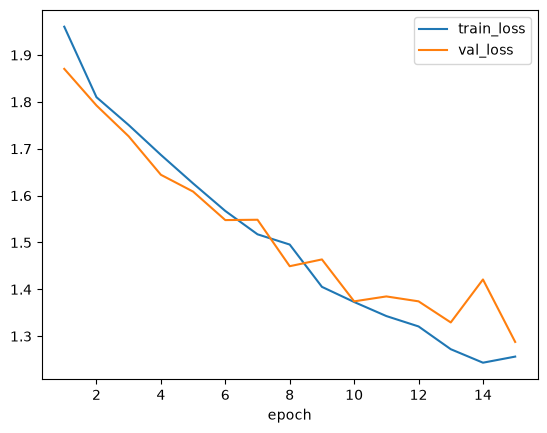

In [48]:
hist = pd.read_csv('../logs/baseline.csv')
hist.to_csv('../results/baseline_history.csv', index=False)
ax = hist.plot(x='epoch', y=['train_loss', 'val_loss'])
ax.figure.savefig('../results/baseline_curves.png', dpi=120)
print(max(history, key=lambda r: r['val_macro_f1']))